In [10]:
import mglearn
mglearn.plots.plot_kmeans_algorithm()

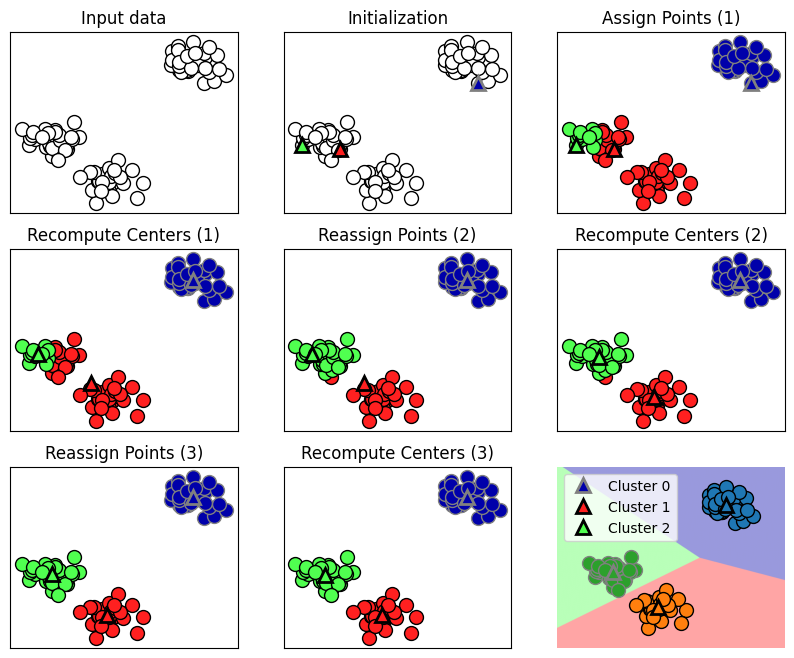

In [11]:
import matplotlib.pyplot as plt
mglearn.plots.plot_kmeans_boundaries()

plt.show()

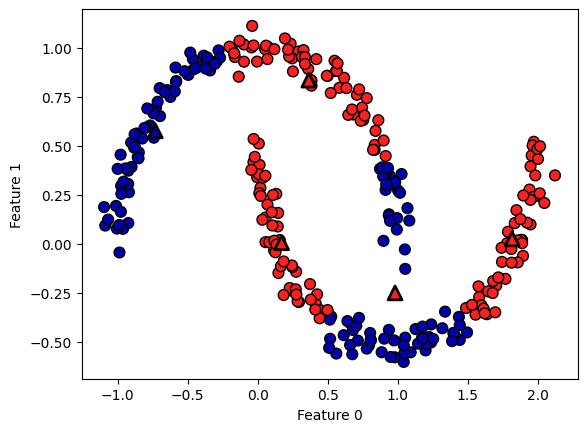

In [12]:
from sklearn.cluster import KMeans

from sklearn.datasets import make_moons
X, y = make_moons(n_samples=300, noise = 0.05, random_state=0)

kmeans = KMeans(n_clusters=5)
kmeans.fit(X)
y_pred = kmeans.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap = mglearn.cm2, s=60, edgecolor = 'k')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            marker='^', c=[mglearn.cm2(0), mglearn.cm2(1), mglearn.cm2(2), mglearn.cm2(3), mglearn.cm2(4)], s=100, linewidth=2,
            edgecolor='k')
plt.xlabel('Feature 0')
plt.ylabel('Feature 1')
plt.show()
#the original code shows that k-means fails but as we can see increasing the cluster numbers help a lot in classification, but we have to find a way to tell the algorithm to group them again based on the cluster's colors.
# And we also have to fine tune it a bit more as we can see the model still fails in some areas.

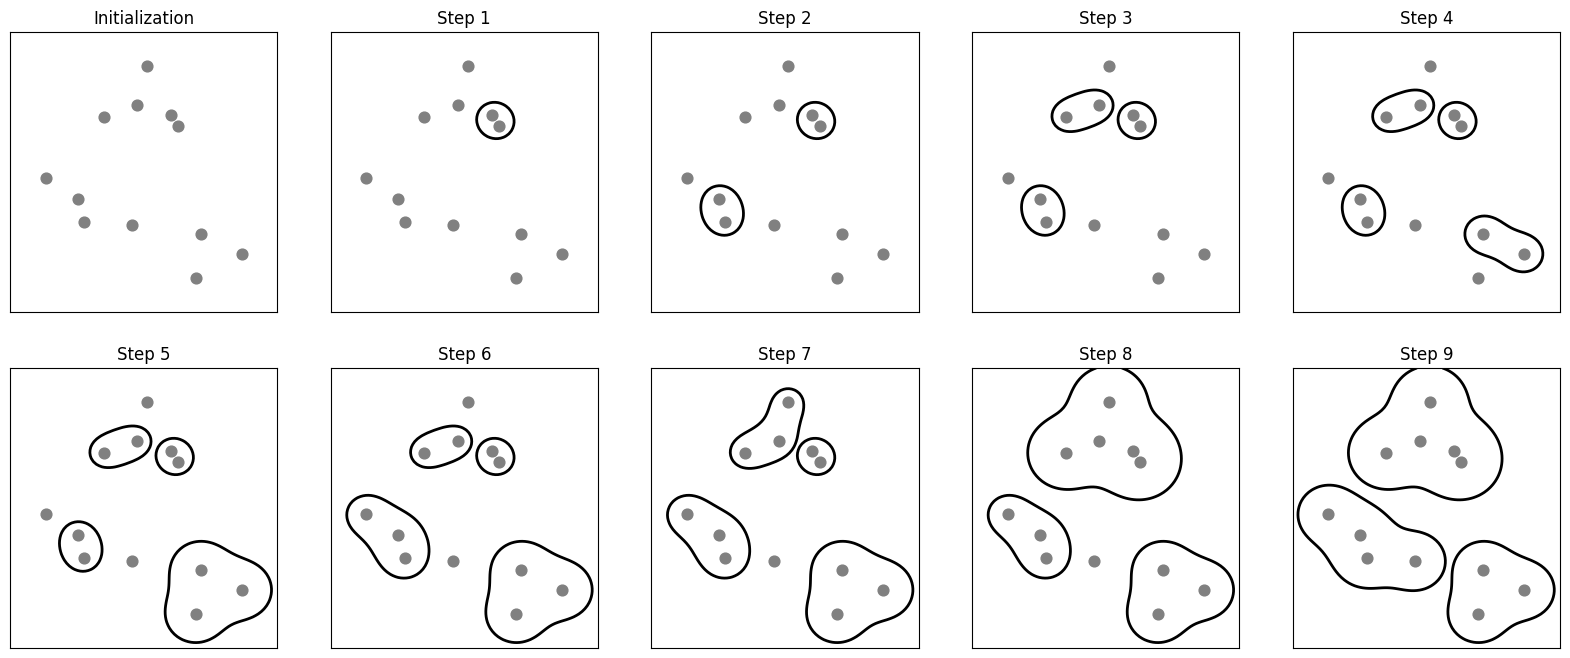

In [13]:
mglearn.plots.plot_agglomerative_algorithm()
plt.show()


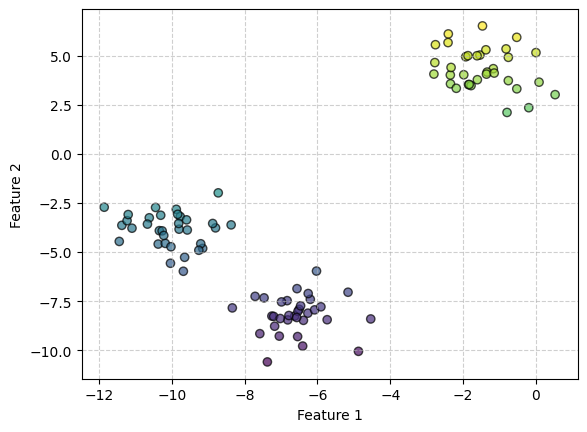

In [32]:
from sklearn.cluster import AgglomerativeClustering
X , y = make_blobs(random_state=1)

## inspecting the data
plt.scatter(X[:, 0],X[:, 1], c=X[:,1], cmap='viridis', edgecolors='k', alpha=0.7)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle = '--', alpha = 0.6)
plt.show()


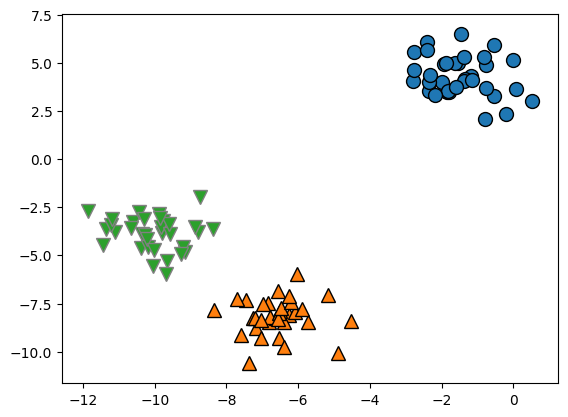

In [31]:
agglo = AgglomerativeClustering(n_clusters=3)
outcome = agglo.fit_predict(X)

mglearn.discrete_scatter(X[:,0], X[:,1], outcome)
plt.show()

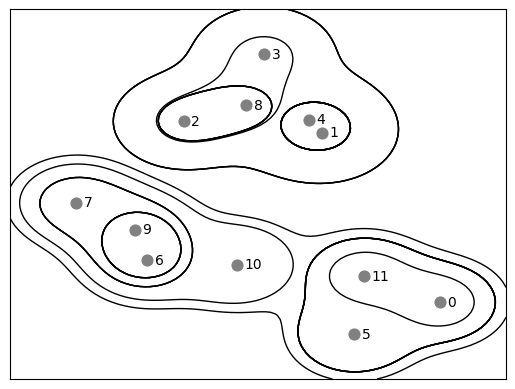

In [33]:
mglearn.plots.plot_agglomerative()
plt.show()

In [8]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
X , y = make_blobs(random_state = 0 , n_samples = 12)

dbscan = DBSCAN()

clusters = dbscan.fit_predict(X)
print(f"Cluster membership: {clusters}")

Cluster membership: [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]


min_samples: 2 eps: 1.000000  cluster: [-1  0  0 -1  0 -1  1  1  0  1 -1 -1]
min_samples: 2 eps: 1.500000  cluster: [0 1 1 1 1 0 2 2 1 2 2 0]
min_samples: 2 eps: 2.000000  cluster: [0 1 1 1 1 0 0 0 1 0 0 0]
min_samples: 2 eps: 3.000000  cluster: [0 0 0 0 0 0 0 0 0 0 0 0]
min_samples: 3 eps: 1.000000  cluster: [-1  0  0 -1  0 -1  1  1  0  1 -1 -1]
min_samples: 3 eps: 1.500000  cluster: [0 1 1 1 1 0 2 2 1 2 2 0]
min_samples: 3 eps: 2.000000  cluster: [0 1 1 1 1 0 0 0 1 0 0 0]
min_samples: 3 eps: 3.000000  cluster: [0 0 0 0 0 0 0 0 0 0 0 0]
min_samples: 5 eps: 1.000000  cluster: [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
min_samples: 5 eps: 1.500000  cluster: [-1  0  0  0  0 -1 -1 -1  0 -1 -1 -1]
min_samples: 5 eps: 2.000000  cluster: [-1  0  0  0  0 -1 -1 -1  0 -1 -1 -1]
min_samples: 5 eps: 3.000000  cluster: [0 0 0 0 0 0 0 0 0 0 0 0]


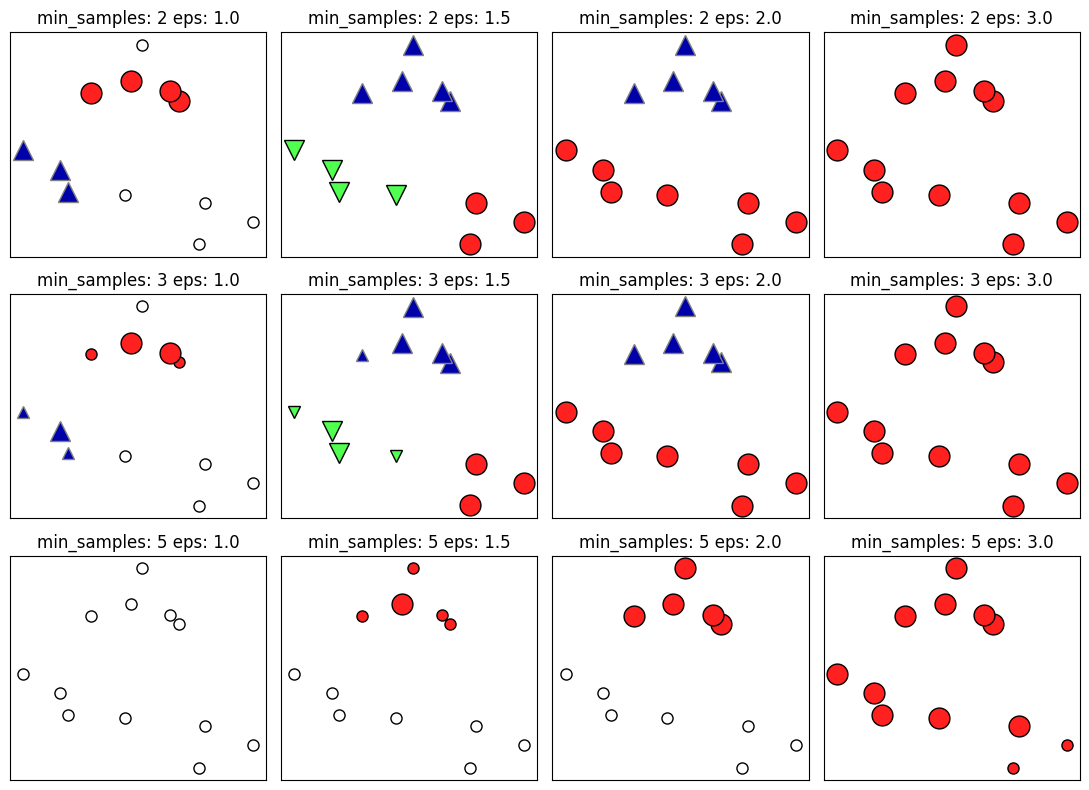

In [9]:
import mglearn
import matplotlib.pyplot as plt
mglearn.plots.plot_dbscan()
plt.show()

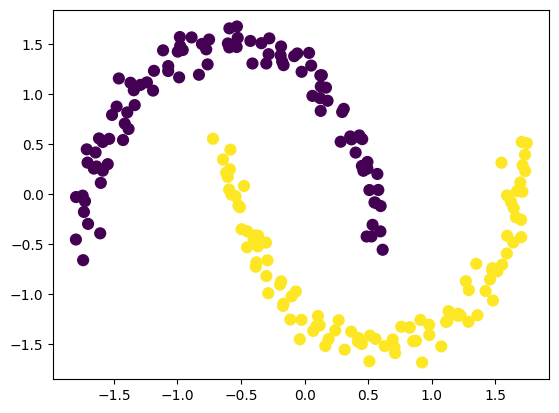

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
X , y = make_moons(n_samples = 200, noise = 0.05 , random_state = 0)

scalar = StandardScaler()
scalar.fit(X)

X_scaled = scalar.transform(X)

dbscan = DBSCAN(min_samples=2, eps=0.5)
clusters = dbscan.fit_predict(X_scaled)

plt.scatter(X_scaled[:,0], X_scaled[:, 1] , c=clusters , cmap = 'viridis' , s=60)
plt.show()



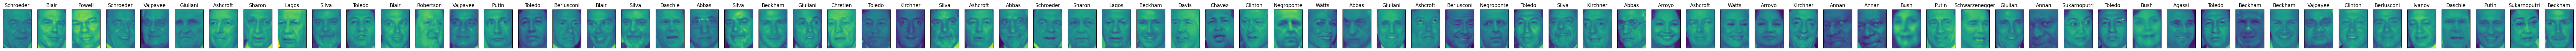

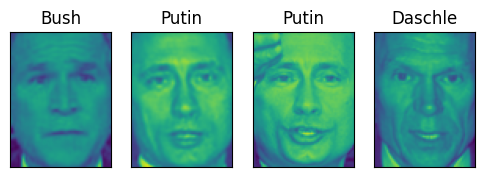

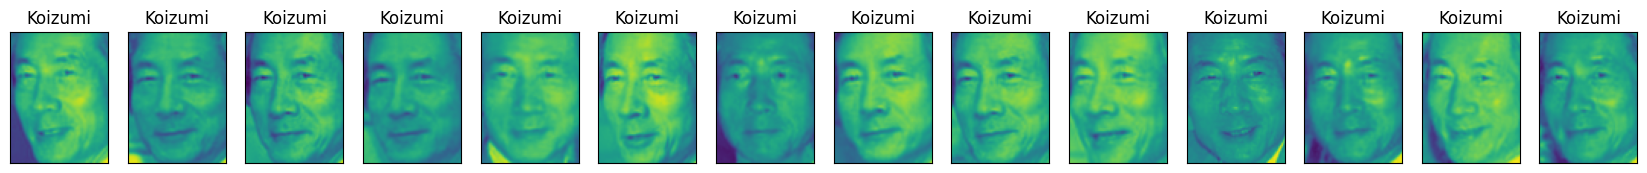

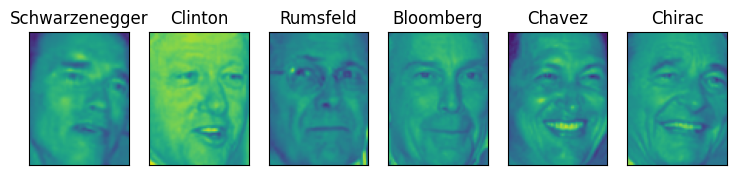

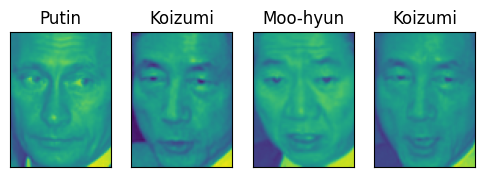

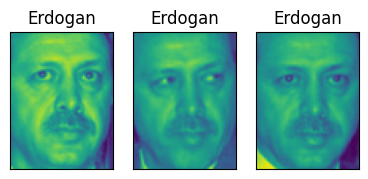

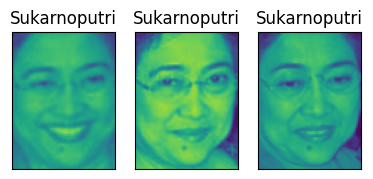

In [13]:
from sklearn.decomposition import PCA
from sklearn.datasets import fetch_lfw_people
import numpy as np
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

## make tTohe data less skewed, we will only take up to 50 images of each person(otherwise, the feature extraction would be overwhelmed by the likelihood of George W. Bush)
people = fetch_lfw_people(min_faces_per_person = 20, resize = 0.7)
image_shape = people.images[0].shape
mask = np.zeros(people.target.shape, dtype=np.bool)
for target in np.unique(people.target):
    mask[np.where(people.target == target)[0][:50]] = 1
X_people = people.data[mask]
y_people = people.target[mask]


pca = PCA(n_components=100, whiten=True, random_state=0)
pca.fit_transform(X_people)
X_pca = pca.transform(X_people)


dbscan = DBSCAN(min_samples=3 , eps= 7)
labels = dbscan.fit_predict(X_pca)

for cluster in range(max(labels) + 1):
    mask = labels == cluster
    n_images = np.sum(mask)
    fig, axes =     plt.subplots(1 , n_images , figsize = (n_images * 1.5 , 4),
                                 subplot_kw = {'xticks':() , 'yticks':()})
    for image , label, ax in zip(X_people[mask], y_people[mask], axes):
        
        ax.imshow(image.reshape(image_shape), vmin=0, vmax=1)
        ax.set_title(people.target_names[label].split()[-1])

plt.show()
